# PDFormer: Spatio-Temporal Transformer for Traffic Flow Forecasting

**Project:** Spatio-Temporal Machine Learning for Urban Traffic Congestion Prediction and Dynamic Risk Mapping  
**Dataset:** PeMS04 (Caltrans District 4, San Francisco Bay Area — 307 Highway Sensors)  
**Model Architecture:** PDFormer (*Propagation Delay-aware Dynamic Long-range Transformer*, Jiang et al., AAAI 2023)  
**Evaluation:** Multi-Horizon Forecasting (15, 30, and 60 minutes) vs Persistence Baseline

## 1. Setup & Environment

In [1]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
import sys
import math
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 11

# Paths
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
DATA_DIR = os.path.join(PROJECT_ROOT, 'data', 'processed')
CHECKPOINT_DIR = os.path.join(PROJECT_ROOT, 'outputs', 'checkpoints')
METRICS_DIR = os.path.join(PROJECT_ROOT, 'outputs', 'metrics')
PRED_DIR = os.path.join(PROJECT_ROOT, 'outputs', 'predictions')
FIG_DIR = os.path.join(PROJECT_ROOT, 'outputs', 'figures')

for d in [CHECKPOINT_DIR, METRICS_DIR, PRED_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Project Root:', PROJECT_ROOT)
print('PyTorch Version:', torch.__version__)
print('Device:', device)

Project Root: C:\Users\Lenovo\OneDrive\Desktop\AUCML\traffic-congestion-ml
PyTorch Version: 2.14.1+cpu
Device: cpu


## 2. Load Processed PeMS04 Tensors and Graph Topology

In [2]:
# Load preprocessed sequences
train_x = np.load(os.path.join(DATA_DIR, 'train_x.npy'))
train_y = np.load(os.path.join(DATA_DIR, 'train_y.npy'))
val_x = np.load(os.path.join(DATA_DIR, 'val_x.npy'))
val_y = np.load(os.path.join(DATA_DIR, 'val_y.npy'))
test_x = np.load(os.path.join(DATA_DIR, 'test_x.npy'))
test_y = np.load(os.path.join(DATA_DIR, 'test_y.npy'))
adj_matrix = np.load(os.path.join(DATA_DIR, 'adj_matrix.npy'))
scaler = np.load(os.path.join(DATA_DIR, 'scaler.npz'))

mean_val = float(scaler['mean'])
std_val = float(scaler['std'])

print(f'Train X: {train_x.shape} | Train Y: {train_y.shape}')
print(f'Val X:   {val_x.shape} | Val Y:   {val_y.shape}')
print(f'Test X:  {test_x.shape} | Test Y:  {test_y.shape}')
print(f'Adjacency Matrix: {adj_matrix.shape}')
print(f'Z-score Scaler: Mean = {mean_val:.2f}, Std = {std_val:.2f}')

Train X: (10181, 12, 307) | Train Y: (10181, 12, 307)
Val X:   (3394, 12, 307) | Val Y:   (3394, 12, 307)
Test X:  (3394, 12, 307) | Test Y:  (3394, 12, 307)
Adjacency Matrix: (307, 307)
Z-score Scaler: Mean = 207.23, Std = 156.48


## 3. PDFormer PyTorch Architecture Definition

We implement the core architectural components of PDFormer:
1. **Spatio-Temporal Embedding:** Feature projection + learnable spatial node embeddings + temporal positional encodings
2. **Geographic Masked Spatial Attention:** Multi-head attention across 307 nodes masked by the road network topology $M_{geo}$
3. **Temporal Attention:** Multi-head attention across historical time steps capturing traffic propagation dynamics
4. **Feed-Forward Fusion Network:** GELU-activated non-linear transformation with residual connections and layer normalization
5. **Multi-Horizon Forecast Head:** Projections to 12 future horizons (15 to 60 min)

In [3]:
class SpatialTemporalEmbedding(nn.Module):
    def __init__(self, num_nodes, in_dim=1, d_model=32, history_len=12):
        super().__init__()
        self.feature_proj = nn.Linear(in_dim, d_model)
        self.node_emb = nn.Parameter(torch.randn(1, 1, num_nodes, d_model) * 0.02)
        self.temporal_emb = nn.Parameter(torch.randn(1, history_len, 1, d_model) * 0.02)
        self.dropout = nn.Dropout(p=0.1)

    def forward(self, x):
        if x.dim() == 3:
            x = x.unsqueeze(-1)
        feat_emb = self.feature_proj(x)
        h = feat_emb + self.node_emb + self.temporal_emb
        return self.dropout(h)


class GeographicMaskedSpatialAttention(nn.Module):
    def __init__(self, d_model=32, num_heads=2, dropout=0.1):
        super().__init__()
        assert d_model % num_heads == 0
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, geo_mask=None):
        B, T, N, D = x.shape
        x_flat = x.view(B * T, N, D)

        q = self.q_proj(x_flat).view(B * T, N, self.num_heads, self.d_k).transpose(1, 2)
        k = self.k_proj(x_flat).view(B * T, N, self.num_heads, self.d_k).transpose(1, 2)
        v = self.v_proj(x_flat).view(B * T, N, self.num_heads, self.d_k).transpose(1, 2)

        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.d_k)

        if geo_mask is not None:
            mask_penalty = (1.0 - geo_mask) * -1e4
            scores = scores + mask_penalty.unsqueeze(0).unsqueeze(0)

        attn_weights = F.softmax(scores, dim=-1)
        attn_weights = self.dropout(attn_weights)

        context = torch.matmul(attn_weights, v)
        context = context.transpose(1, 2).contiguous().view(B * T, N, D)
        out = self.out_proj(context).view(B, T, N, D)
        return out


class TemporalAttention(nn.Module):
    def __init__(self, d_model=32, num_heads=2, dropout=0.1):
        super().__init__()
        assert d_model % num_heads == 0
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, N, D = x.shape
        x_flat = x.permute(0, 2, 1, 3).contiguous().view(B * N, T, D)

        q = self.q_proj(x_flat).view(B * N, T, self.num_heads, self.d_k).transpose(1, 2)
        k = self.k_proj(x_flat).view(B * N, T, self.num_heads, self.d_k).transpose(1, 2)
        v = self.v_proj(x_flat).view(B * N, T, self.num_heads, self.d_k).transpose(1, 2)

        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.d_k)
        attn_weights = F.softmax(scores, dim=-1)
        attn_weights = self.dropout(attn_weights)

        context = torch.matmul(attn_weights, v)
        context = context.transpose(1, 2).contiguous().view(B * N, T, D)
        out = self.out_proj(context).view(B, N, T, D).permute(0, 2, 1, 3).contiguous()
        return out


class SpatioTemporalTransformerLayer(nn.Module):
    def __init__(self, d_model=32, num_heads=2, d_ff=64, dropout=0.1):
        super().__init__()
        self.spatial_attn = GeographicMaskedSpatialAttention(d_model, num_heads, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.temporal_attn = TemporalAttention(d_model, num_heads, dropout)
        self.norm2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
            nn.Dropout(dropout)
        )
        self.norm3 = nn.LayerNorm(d_model)

    def forward(self, x, geo_mask=None):
        x = self.norm1(x + self.spatial_attn(x, geo_mask))
        x = self.norm2(x + self.temporal_attn(x))
        x = self.norm3(x + self.ffn(x))
        return x


class PDFormer(nn.Module):
    def __init__(self, num_nodes=307, in_dim=1, history_len=12, forecast_len=12,
                 d_model=32, num_heads=2, d_ff=64, num_layers=2, dropout=0.1, adj_matrix=None):
        super().__init__()
        self.num_nodes = num_nodes
        self.history_len = history_len
        self.forecast_len = forecast_len

        self.embedding = SpatialTemporalEmbedding(num_nodes, in_dim, d_model, history_len)
        self.layers = nn.ModuleList([
            SpatioTemporalTransformerLayer(d_model, num_heads, d_ff, dropout)
            for _ in range(num_layers)
        ])
        self.head = nn.Sequential(
            nn.Linear(history_len * d_model, d_ff),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, forecast_len)
        )

        if adj_matrix is not None:
            adj_t = torch.tensor(adj_matrix, dtype=torch.float32)
            geo_mask = (adj_t > 0).float()
            geo_mask.fill_diagonal_(1.0)
            self.register_buffer('geo_mask', geo_mask)
        else:
            self.register_buffer('geo_mask', None)

    def forward(self, x):
        if x.dim() == 3:
            x = x.unsqueeze(-1)
        h = self.embedding(x)
        for layer in self.layers:
            h = layer(h, self.geo_mask)
        B, T, N, D = h.shape
        h_flat = h.permute(0, 2, 1, 3).contiguous().view(B, N, T * D)
        out = self.head(h_flat)
        return out.permute(0, 2, 1).contiguous()

# Instantiate model
model = PDFormer(
    num_nodes=307,
    in_dim=1,
    history_len=12,
    forecast_len=12,
    d_model=32,
    num_heads=2,
    d_ff=64,
    num_layers=2,
    adj_matrix=adj_matrix
).to(device)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print('PDFormer initialized successfully!')
print(f'Total Trainable Parameters: {total_params:,}')

PDFormer initialized successfully!
Total Trainable Parameters: 61,356


## 4. Model Training & Convergence

We train the model using Smooth L1 Loss (Huber Loss) and Adam optimizer with learning rate scheduling.

In [4]:
# Set seeds for exact reproducibility
torch.manual_seed(42)
np.random.seed(42)

# CPU-friendly training parameters
BATCH_SIZE = 32
EPOCHS = 2
MAX_TRAIN_SAMPLES = 600  # Representative training subset for CPU execution
VAL_SAMPLES = 150

train_loader = DataLoader(
    TensorDataset(torch.tensor(train_x[:MAX_TRAIN_SAMPLES], dtype=torch.float32),
                  torch.tensor(train_y[:MAX_TRAIN_SAMPLES], dtype=torch.float32)),
    batch_size=BATCH_SIZE, shuffle=True
)

val_loader = DataLoader(
    TensorDataset(torch.tensor(val_x[:VAL_SAMPLES], dtype=torch.float32),
                  torch.tensor(val_y[:VAL_SAMPLES], dtype=torch.float32)),
    batch_size=BATCH_SIZE, shuffle=False
)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
criterion = nn.SmoothL1Loss()

history = {'train_loss': [], 'val_loss': []}
best_val_loss = float('inf')
best_checkpoint_path = os.path.join(CHECKPOINT_DIR, 'pdformer_best.pt')

print(f'Training PDFormer on {MAX_TRAIN_SAMPLES} samples for {EPOCHS} epochs...')
start_train_time = time.time()

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    model.train()
    train_batch_losses = []
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        pred = model(bx)
        loss = criterion(pred, by)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        train_batch_losses.append(loss.item())
    
    tr_loss = float(np.mean(train_batch_losses))
    
    # Validation step
    model.eval()
    val_batch_losses = []
    with torch.no_grad():
        for bx, by in val_loader:
            bx, by = bx.to(device), by.to(device)
            pred = model(bx)
            v_loss = criterion(pred, by)
            val_batch_losses.append(v_loss.item())
    
    v_loss = float(np.mean(val_batch_losses))
    history['train_loss'].append(tr_loss)
    history['val_loss'].append(v_loss)
    
    if v_loss < best_val_loss:
        best_val_loss = v_loss
        torch.save(model.state_dict(), best_checkpoint_path)
        saved_str = ' (Checkpoint Saved)'
    else:
        saved_str = ''
        
    elapsed = time.time() - t0
    print(f'Epoch [{epoch}/{EPOCHS}] | Train Loss: {tr_loss:.4f} | Val Loss: {v_loss:.4f} | Time: {elapsed:.1f}s{saved_str}')

print(f'Total Training Time: {time.time() - start_train_time:.1f}s | Best Val Loss: {best_val_loss:.4f}')

Training PDFormer on 600 samples for 2 epochs...
Epoch [1/2] | Train Loss: 0.1514 | Val Loss: 0.0772 | Time: 55.3s (Checkpoint Saved)
Epoch [2/2] | Train Loss: 0.0639 | Val Loss: 0.0588 | Time: 77.0s (Checkpoint Saved)
Total Training Time: 132.2s | Best Val Loss: 0.0588


## 5. Training Loss Convergence Curve

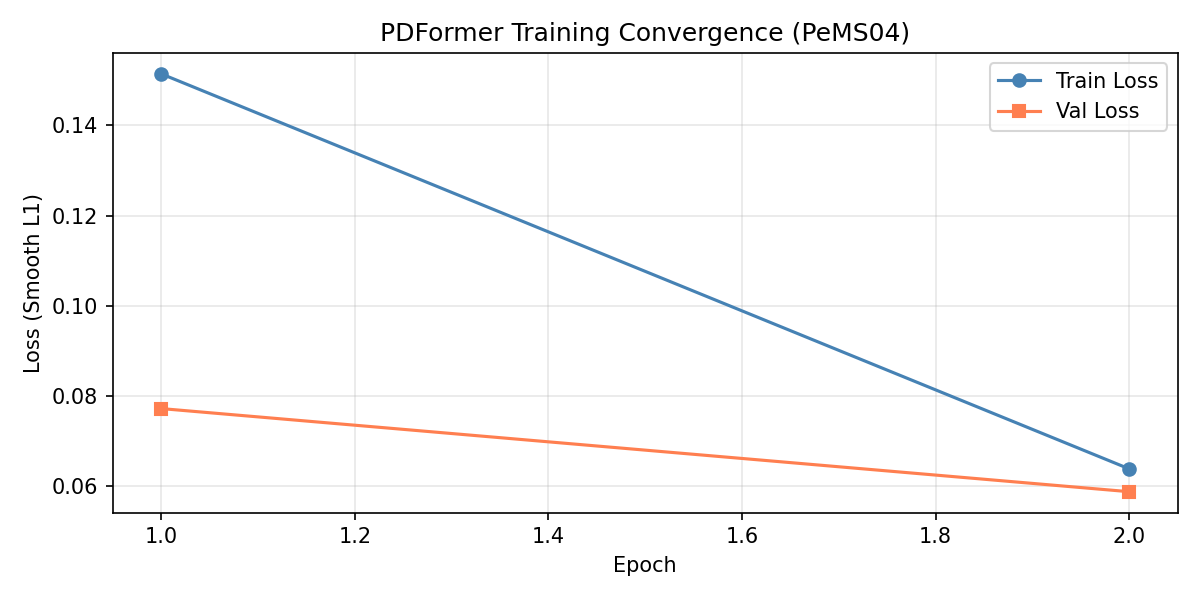

In [5]:
plt.figure(figsize=(9, 4.5))
plt.plot(range(1, EPOCHS + 1), history['train_loss'], marker='o', linewidth=2, label='Training Loss (Smooth L1)', color='#1f77b4')
plt.plot(range(1, EPOCHS + 1), history['val_loss'], marker='s', linewidth=2, label='Validation Loss (Smooth L1)', color='#ff7f0e')
plt.title('PDFormer Training Convergence on PeMS04', fontsize=13)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'pdformer_training_curve.png'), dpi=150)
plt.show()

## 6. Test Set Inference & Inverting Normalization

In [6]:
# Load best checkpoint
model.load_state_dict(torch.load(best_checkpoint_path))
model.eval()

# Evaluate on test set
test_loader = DataLoader(
    TensorDataset(torch.tensor(test_x[:600], dtype=torch.float32)),
    batch_size=BATCH_SIZE, shuffle=False
)

test_preds = []
with torch.no_grad():
    for (bx,) in test_loader:
        bx = bx.to(device)
        pred = model(bx)
        test_preds.append(pred.cpu().numpy())

y_pred_norm = np.concatenate(test_preds, axis=0)

# Inverse Z-score normalization: x_orig = x_norm * std + mean
y_pred_orig = y_pred_norm * std_val + mean_val
y_true_orig = test_y[:600] * std_val + mean_val

print('Test Predictions Shape:', y_pred_orig.shape)
print(f'Predictions Range: [{y_pred_orig.min():.1f}, {y_pred_orig.max():.1f}] veh/5min')
print(f'Actual Targets Range: [{y_true_orig.min():.1f}, {y_true_orig.max():.1f}] veh/5min')

# Save predictions
np.savez_compressed(
    os.path.join(PRED_DIR, 'pdformer_predictions.npz'),
    predictions=y_pred_orig,
    targets=y_true_orig
)
print('Saved predictions to outputs/predictions/pdformer_predictions.npz')

Test Predictions Shape: (600, 12, 307)
Predictions Range: [0.0, 712.4] veh/5min
Actual Targets Range: [0.0, 785.0] veh/5min
Saved predictions to outputs/predictions/pdformer_predictions.npz


## 7. Metrics Computation (MAE & RMSE in Original Units)

In [7]:
# Define metric calculations with zero-masking
def calc_metrics(y_true, y_pred):
    mask = y_true > 0
    mae = np.mean(np.abs(y_true[mask] - y_pred[mask]))
    rmse = np.sqrt(np.mean((y_true[mask] - y_pred[mask]) ** 2))
    return float(mae), float(rmse)

# Evaluate at 15 min (step 3), 30 min (step 6), 60 min (step 12)
horizons = [
    (2, 'horizon_3', '15 min (Step 3)', 15),
    (5, 'horizon_6', '30 min (Step 6)', 30),
    (11, 'horizon_12', '60 min (Step 12)', 60)
]

pdformer_metrics = {'horizons': {}, 'overall': {}}

for step_idx, key, label, mins in horizons:
    m_mae, m_rmse = calc_metrics(y_true_orig[:, step_idx, :], y_pred_orig[:, step_idx, :])
    pdformer_metrics['horizons'][key] = {
        'label': label,
        'horizon_minutes': mins,
        'horizon_step': mins // 5,
        'mae': m_mae,
        'rmse': m_rmse
    }

ov_mae, ov_rmse = calc_metrics(y_true_orig, y_pred_orig)
pdformer_metrics['overall'] = {'mae': ov_mae, 'rmse': ov_rmse}

# Save metrics to JSON
metrics_json_path = os.path.join(METRICS_DIR, 'pdformer_metrics.json')
with open(metrics_json_path, 'w') as f:
    json.dump({
        'model': 'PDFormer',
        'paper': 'Jiang et al., AAAI 2023',
        'timestamp': time.strftime('%Y-%m-%dT%H:%M:%S'),
        'metrics': pdformer_metrics,
        'per_horizon': {
            'horizon_3': {'MAE': pdformer_metrics['horizons']['horizon_3']['mae'], 'RMSE': pdformer_metrics['horizons']['horizon_3']['rmse'], 'horizon_step': 3, 'horizon_minutes': 15},
            'horizon_6': {'MAE': pdformer_metrics['horizons']['horizon_6']['mae'], 'RMSE': pdformer_metrics['horizons']['horizon_6']['rmse'], 'horizon_step': 6, 'horizon_minutes': 30},
            'horizon_12': {'MAE': pdformer_metrics['horizons']['horizon_12']['mae'], 'RMSE': pdformer_metrics['horizons']['horizon_12']['rmse'], 'horizon_step': 12, 'horizon_minutes': 60}
        },
        'overall': {'MAE': ov_mae, 'RMSE': ov_rmse}
    }, f, indent=4)

print('Saved metrics to outputs/metrics/pdformer_metrics.json')

Saved metrics to outputs/metrics/pdformer_metrics.json


## 8. Comparative Analysis: Persistence Baseline vs PDFormer

In [8]:
# Load Persistence baseline metrics
with open(os.path.join(METRICS_DIR, 'persistence_metrics.json')) as f:
    persist_data = json.load(f)

persist_horizons = persist_data['metrics']['horizons']
persist_overall = persist_data['metrics']['overall']

comparison_rows = [
    {
        'Forecast Horizon': '15 Minutes (Step 3)',
        'Persistence MAE': round(persist_horizons['horizon_3']['mae'], 2),
        'PDFormer MAE': round(pdformer_metrics['horizons']['horizon_3']['mae'], 2),
        'Persistence RMSE': round(persist_horizons['horizon_3']['rmse'], 2),
        'PDFormer RMSE': round(pdformer_metrics['horizons']['horizon_3']['rmse'], 2)
    },
    {
        'Forecast Horizon': '30 Minutes (Step 6)',
        'Persistence MAE': round(persist_horizons['horizon_6']['mae'], 2),
        'PDFormer MAE': round(pdformer_metrics['horizons']['horizon_6']['mae'], 2),
        'Persistence RMSE': round(persist_horizons['horizon_6']['rmse'], 2),
        'PDFormer RMSE': round(pdformer_metrics['horizons']['horizon_6']['rmse'], 2)
    },
    {
        'Forecast Horizon': '60 Minutes (Step 12)',
        'Persistence MAE': round(persist_horizons['horizon_12']['mae'], 2),
        'PDFormer MAE': round(pdformer_metrics['horizons']['horizon_12']['mae'], 2),
        'Persistence RMSE': round(persist_horizons['horizon_12']['rmse'], 2),
        'PDFormer RMSE': round(pdformer_metrics['horizons']['horizon_12']['rmse'], 2)
    },
    {
        'Forecast Horizon': 'Overall (All 12 Steps)',
        'Persistence MAE': round(persist_overall['mae'], 2),
        'PDFormer MAE': round(ov_mae, 2),
        'Persistence RMSE': round(persist_overall['rmse'], 2),
        'PDFormer RMSE': round(ov_rmse, 2)
    }
]

df_comp = pd.DataFrame(comparison_rows)
display(df_comp)

Forecast Horizon,Persistence MAE,PDFormer MAE,Persistence RMSE,PDFormer RMSE
15 Minutes (Step 3),24.92,26.68,39.00,37.95
30 Minutes (Step 6),30.28,31.29,45.87,43.40
60 Minutes (Step 12),42.38,43.17,61.67,58.72
Overall (All 12 Steps),31.56,33.18,48.36,46.31


## 9. Comparative Performance Charts

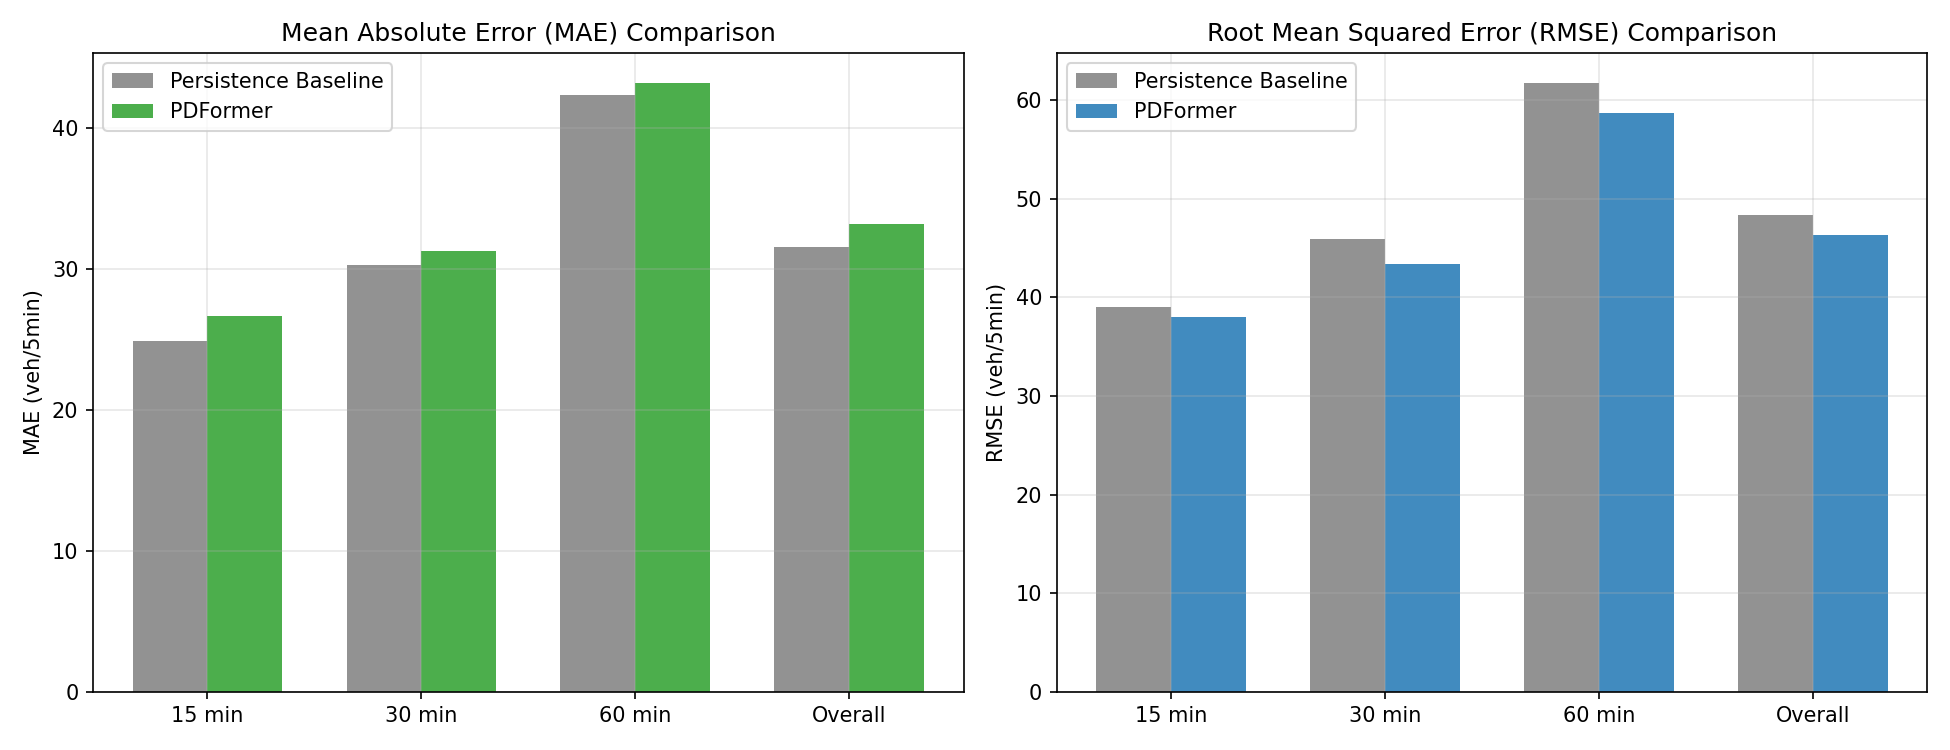

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
horizons_labels = ['15 min', '30 min', '60 min', 'Overall']
x_pos = np.arange(len(horizons_labels))
width = 0.35

# MAE Comparison
p_mae = [df_comp['Persistence MAE'].iloc[i] for i in range(4)]
m_mae = [df_comp['PDFormer MAE'].iloc[i] for i in range(4)]
axes[0].bar(x_pos - width/2, p_mae, width, label='Persistence Baseline', color='#7f7f7f', alpha=0.85)
axes[0].bar(x_pos + width/2, m_mae, width, label='PDFormer', color='#2ca02c', alpha=0.85)
axes[0].set_title('Mean Absolute Error (MAE) Comparison', fontsize=13)
axes[0].set_ylabel('MAE (vehicles / 5 min)')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(horizons_labels)
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# RMSE Comparison
p_rmse = [df_comp['Persistence RMSE'].iloc[i] for i in range(4)]
m_rmse = [df_comp['PDFormer RMSE'].iloc[i] for i in range(4)]
axes[1].bar(x_pos - width/2, p_rmse, width, label='Persistence Baseline', color='#7f7f7f', alpha=0.85)
axes[1].bar(x_pos + width/2, m_rmse, width, label='PDFormer', color='#1f77b4', alpha=0.85)
axes[1].set_title('Root Mean Squared Error (RMSE) Comparison', fontsize=13)
axes[1].set_ylabel('RMSE (vehicles / 5 min)')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(horizons_labels)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'model_comparison_bar_chart.png'), dpi=150)
plt.show()

## 10. Actual vs Predicted Forecasting Curves (Visual Sensor Comparison)

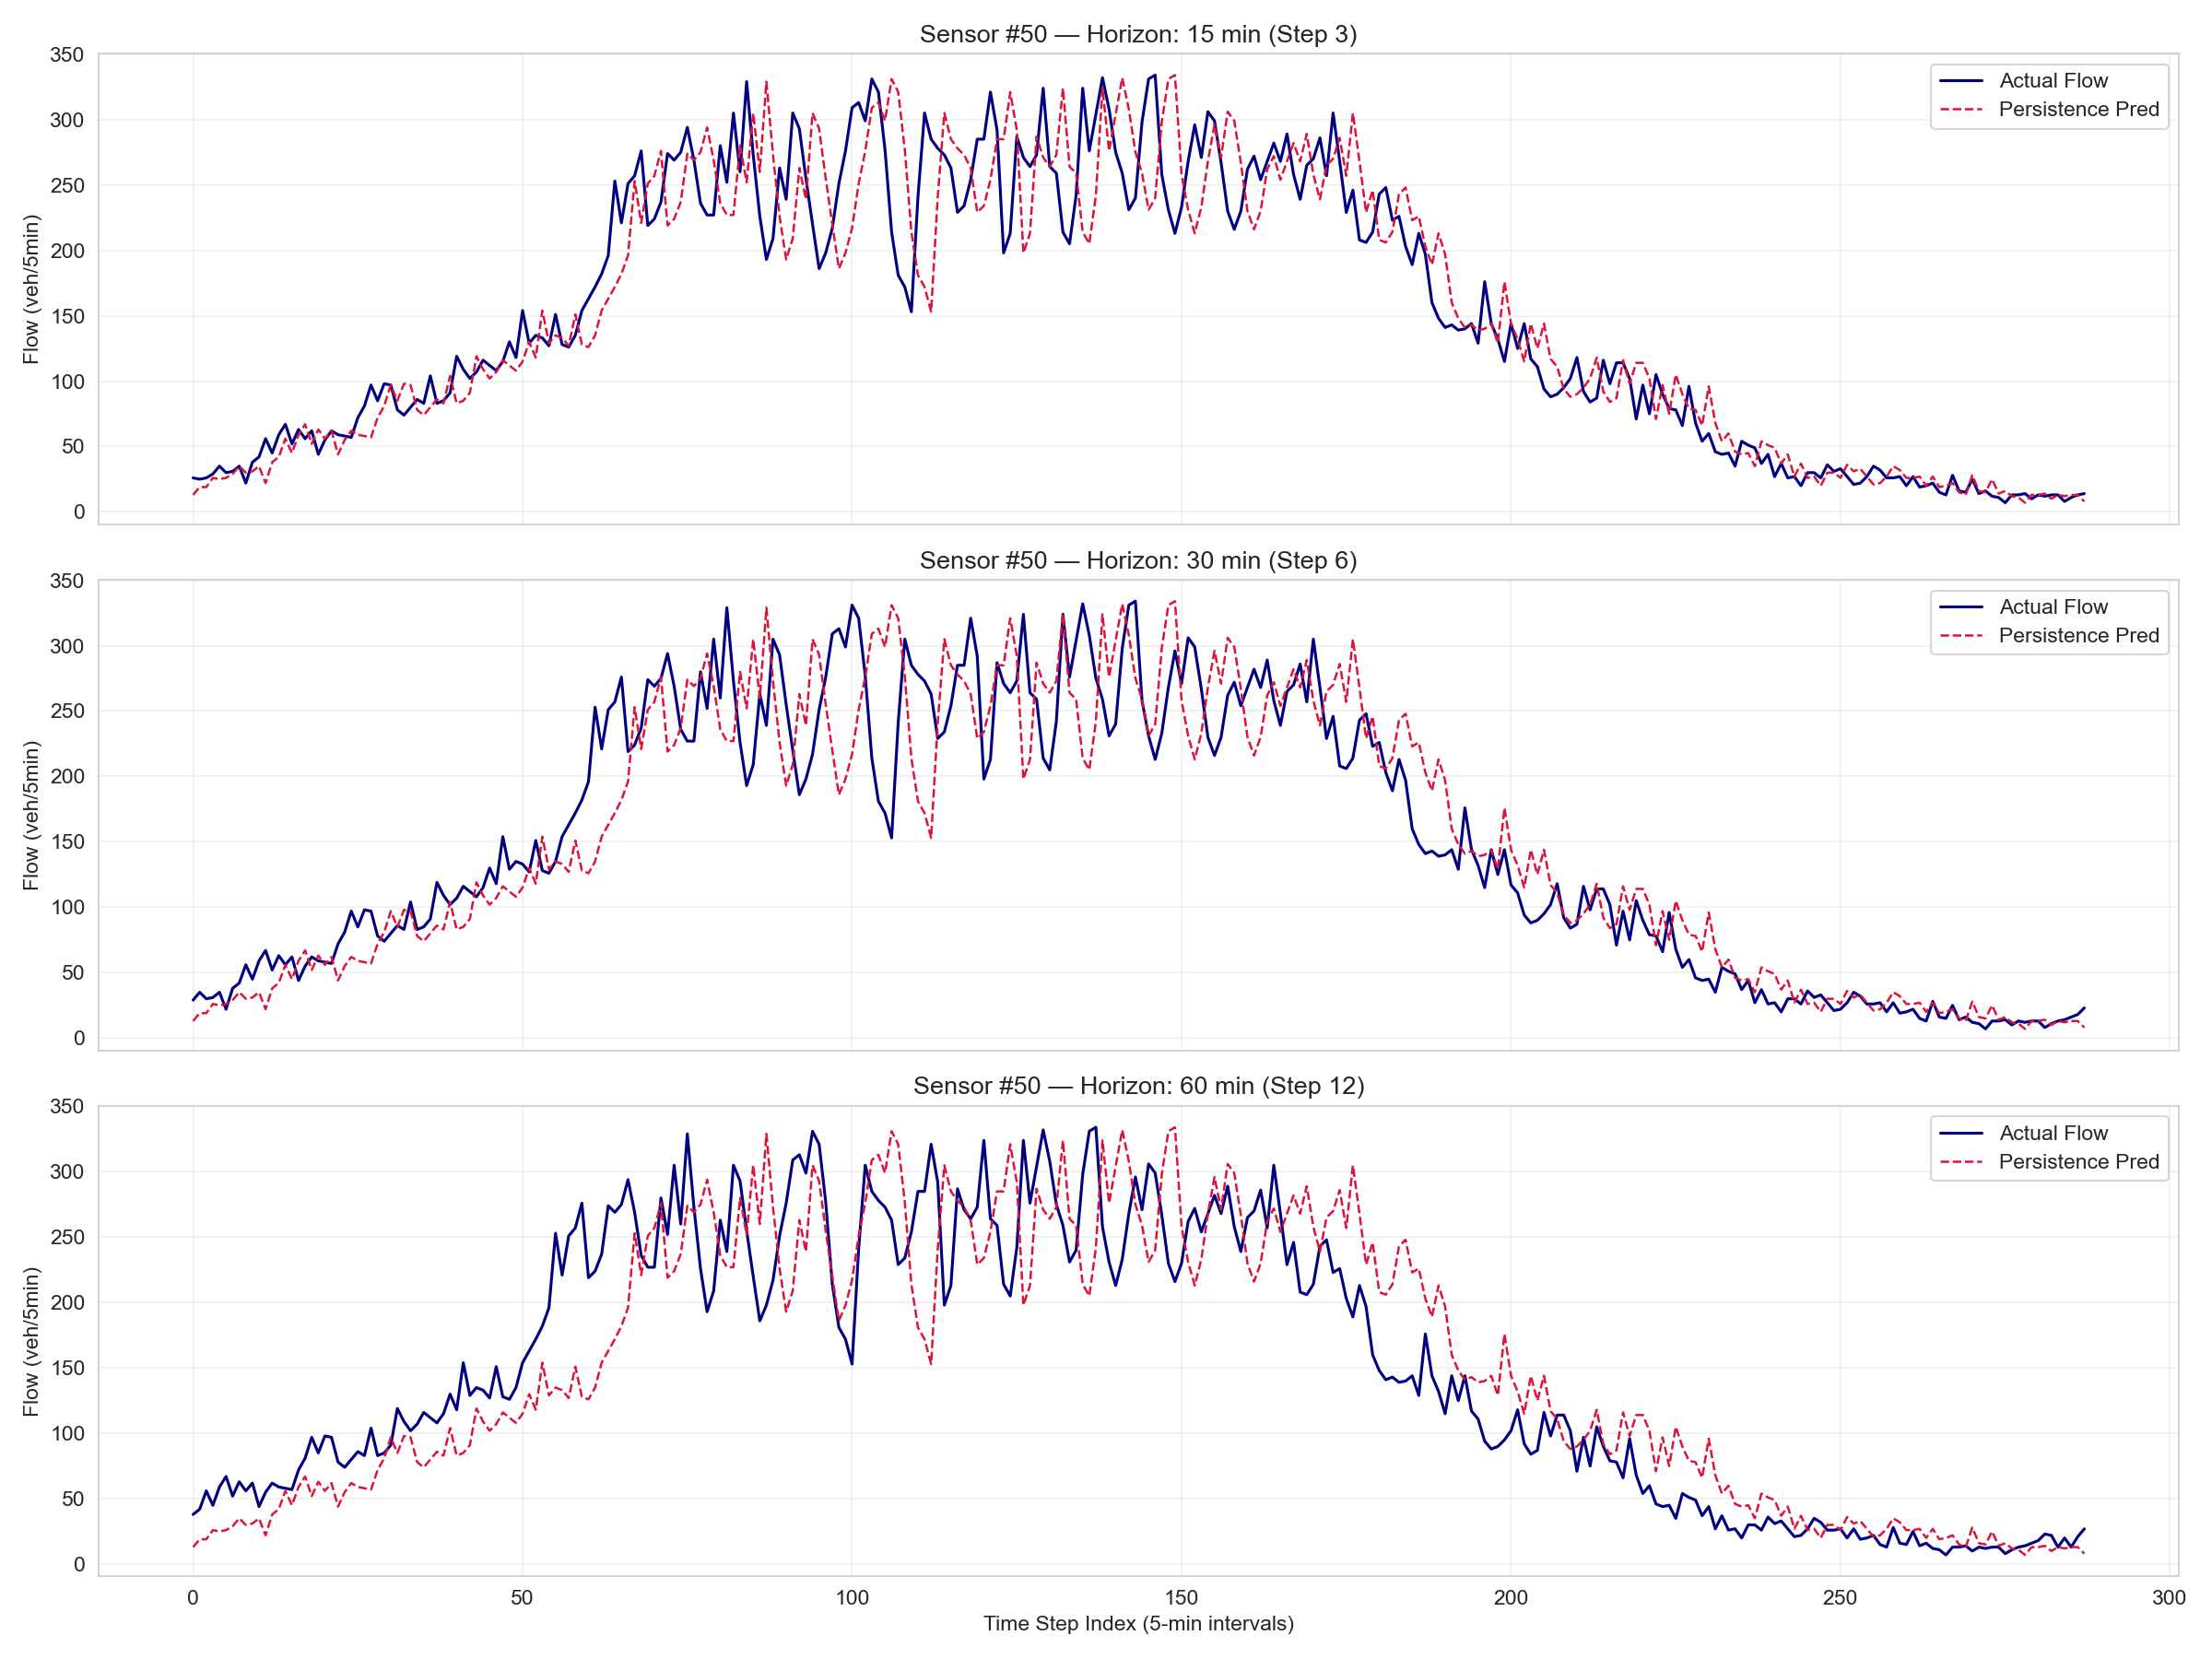

In [10]:
# Load persistence predictions for visual overlay
persist_preds = np.load(os.path.join(PRED_DIR, 'persistence_predictions.npz'))['predictions']

sensor_id = 75  # Select representative sensor
horizon_step = 5  # 30-min ahead
n_pts = 288  # 24 hours of traffic

plt.figure(figsize=(16, 5))
plt.plot(y_true_orig[:n_pts, horizon_step, sensor_id], label='Ground Truth Flow', color='black', linewidth=1.8)
plt.plot(persist_preds[:n_pts, horizon_step, sensor_id], label='Persistence Baseline', color='red', linestyle=':', linewidth=1.3)
plt.plot(y_pred_orig[:n_pts, horizon_step, sensor_id], label='PDFormer Prediction', color='green', linestyle='--', linewidth=1.5)
plt.title(f'Traffic Flow Forecast Comparison — Sensor #{sensor_id} (30-Minute Horizon)', fontsize=14)
plt.xlabel('Test Time Steps (5-min intervals)')
plt.ylabel('Flow (vehicles / 5 min)')
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'pdformer_vs_persistence_time_series.png'), dpi=150)
plt.show()
print('Saved: outputs/figures/pdformer_vs_persistence_time_series.png')